# Quantum phase transitions with Qiskit
### Finding the ground state of the Ising chain with a variational quantum algorithm

In this tutorial you will use a quantum algorithm, the **variational quantum eigensolver (VQE)**, to study a **quantum phase transition** in a chain of qubits. You will:

1. write the Hamiltonian of the Ising model with Qiskit;
2. find its lowest-energy state, the **ground state**, with VQE;
3. measure how magnetized the chain is, and watch the phase transition appear, and get sharper, as the chain gets longer.

**What you need to know:** basic Python, and the basics of qubits and of the Pauli matrices $X$ and $Z$.
**Software:** Qiskit 2.x, NumPy, SciPy and Matplotlib.

*Adapted from the PennyLane demo [“Seeing quantum phase transitions with quantum computers”](https://pennylane.ai/qml/demos/tutorial_quantum_phase_transitions) by Damian Pope and Tirth Shah. Rewritten for Qiskit and adapted for this hackaton. The figures are from the original demo.*

In [159]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import efficient_su2
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit.quantum_info import SparsePauliOp, Statevector

print("Qiskit version:", qiskit.__version__)

# One color and one marker per chain length, used in every figure
SIZE_COLORS = {4: "#2a78d6", 5: "#eb6834", 6: "#1baf7a", 8: "#eda100", 10: "#e87ba4"}
SIZE_MARKERS = {4: "o", 5: "x", 6: "s", 8: "^", 10: "D"}
plt.rcParams.update({"figure.figsize": (6.4, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

Qiskit version: 2.6.1


## 1. What is a phase transition?

A **phase transition** is an abrupt change in the properties of a system when one of its parameters is varied. Water freezing into ice when the temperature drops below 0 °C is the everyday example. Phase transitions appear everywhere in physics, from magnets and superconductors to the early universe.

A **quantum** phase transition happens at zero temperature. It is driven not by heat but by *quantum fluctuations*, a consequence of Heisenberg's uncertainty principle: changing a parameter in the Hamiltonian changes the nature of the ground state. For large systems these transitions may be very hard to compute on classical computers (it is not just a matter of size, it generally depends also on the degree of entanglement in the system), which is one reason why physicists want to study them on quantum computers.

Today's exercise is in the proof of concept domain: we won't do anything a classical computer couldn't do efficiently, it is a simple example with didactical purposes.

## 2. The Ising model

The simplest Ising model is a chain of $N$ qubits on a line. Think of each qubit as a small magnet (a *spin*) that can point up ($|0\rangle$) or down ($|1\rangle$) along $z$. Each spin interacts with its neighbours on either side.

<center><img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_1_Ising_chain.png" width="30%" alt="A chain of qubits, each interacting with its nearest neighbours"></center>

The energy of the chain is given by the Hamiltonian

$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1},$$

where $Z_i$ is the Pauli-$Z$ operator acting on qubit $i$ and $J > 0$ is the strength of the interaction. Each term gives $-J$ when two neighbours point the same way and $+J$ when they point opposite ways, so the energy is lowest when all spins agree.

In Qiskit, Hamiltonians are written as sums of *Pauli strings* with `SparsePauliOp`. Note that Qiskit prints the strings with qubit 0 on the **right**: `"IZZ"` means $Z$ on qubits 0 and 1, and nothing (the identity $I$) on qubit 2. The function below also has a second term, the *transverse field*, which we will use later; for now it is switched off ($h_x = 0$).

#### Qiskit note: `SparsePauliOp`

A `SparsePauliOp` stores an operator as a sum of Pauli strings with coefficients, $H = \sum_k c_k P_k$. `SparsePauliOp.from_sparse_list(terms, num_qubits)` builds it from a list of tuples `(Pauli string, qubit indices, coefficient)`: for example `("ZZ", [1, 2], -2)` is the term $-2\,Z_1 Z_2$, and every qubit not listed gets the identity $I$. [Full documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.SparsePauliOp).

In [160]:
def ising_hamiltonian(N, J, h_x=0.0):
    # Open chain:  H = -J * sum_i Z_i Z_{i+1}  -  h_x * sum_i X_i
    terms = [("ZZ", [i, i + 1], -J) for i in range(N - 1)]
    if h_x != 0:
        terms += [("X", [i], -h_x) for i in range(N)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=N)

    # Same function written without list comprehensions:
    #
    # terms = []                               # each term is (Pauli string, qubits it acts on, coefficient)
    #
    # # Interaction: one -J * Z_i Z_{i+1} term for every pair of neighbours
    # for i in range(N - 1):
    #     term = ("ZZ", [i, i + 1], -J)
    #     terms.append(term)
    #
    # # Transverse field: one -h_x * X_i term on every qubit (only if h_x is not zero)
    # if h_x != 0:
    #     for i in range(N):
    #         term = ("X", [i], -h_x)
    #         terms.append(term)
    #
    # H = SparsePauliOp.from_sparse_list(terms, num_qubits=N)
    # return H


N = 3
J = 2

H = ising_hamiltonian(N, J)
print(f"H = {H}")

H = SparsePauliOp(['IZZ', 'ZZI'],
              coeffs=[-2.+0.j, -2.+0.j])


## 3. Finding the ground state with VQE

The **ground state** is the state of lowest energy. For three qubits we can guess it, but in general we need an algorithm. The **variational quantum eigensolver (VQE)** works like this:

1. A quantum circuit with adjustable rotation angles $\boldsymbol\theta$ prepares a trial state $|\psi(\boldsymbol\theta)\rangle$. This circuit is called the **ansatz**.
2. The quantum computer measures the energy $E(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)|H|\psi(\boldsymbol\theta)\rangle$.
3. A classical optimizer changes $\boldsymbol\theta$ to lower the energy, and steps 2 and 3 are repeated.

The **variational principle** guarantees that $E(\boldsymbol\theta)$ is never below the true ground-state energy, so the lowest energy we find is our best estimate of it.

As ansatz we use the **hardware-efficient ansatz** [2], which is easy to run on real devices:

1. three rotations ($R_Z$, $R_X$, $R_Z$) on each qubit, each with its own angle;
2. a CNOT gate between each pair of neighbouring qubits;
3. another three rotations ($R_Z$, $R_X$, $R_Z$) on each qubit.

That makes $6N$ angles in total.

In [161]:
def create_ansatz(N):
    # Hardware-efficient ansatz with 6N parameters θ[0], ..., θ[6N-1]
    theta = ParameterVector("θ", 6 * N)
    qc = QuantumCircuit(N)
    # STEP 1: single-qubit rotations on all the qubits
    for i in range(N):
        qc.rz(theta[i], i)
        qc.rx(theta[N + i], i)
        qc.rz(theta[2 * N + i], i)
    # STEP 2: a CNOT gate on each pair of neighbouring qubits
    for i in range(N - 1):
        qc.cx(i, i + 1)
    # STEP 3: single-qubit rotations on all the qubits
    for i in range(N):
        qc.rz(theta[3 * N + i], i)
        qc.rx(theta[4 * N + i], i)
        qc.rz(theta[5 * N + i], i)
    return qc


def use_premade_ansatz(N):
    # this is the same circuit, but from library
    return efficient_su2(N, su2_gates=["rz", "rx", "rz"], entanglement="linear", reps=1)


ansatz = create_ansatz(N)
# ansatz = use_premade_ansatz(N)  # gives exactly the same circuit
print(ansatz.draw("text", fold=-1))

     ┌──────────┐┌──────────┐┌──────────┐     ┌──────────┐┌───────────┐┌───────────┐             
q_0: ┤ Rz(θ[0]) ├┤ Rx(θ[3]) ├┤ Rz(θ[6]) ├──■──┤ Rz(θ[9]) ├┤ Rx(θ[12]) ├┤ Rz(θ[15]) ├─────────────
     ├──────────┤├──────────┤├──────────┤┌─┴─┐└──────────┘├───────────┤├───────────┤┌───────────┐
q_1: ┤ Rz(θ[1]) ├┤ Rx(θ[4]) ├┤ Rz(θ[7]) ├┤ X ├─────■──────┤ Rz(θ[10]) ├┤ Rx(θ[13]) ├┤ Rz(θ[16]) ├
     ├──────────┤├──────────┤├──────────┤└───┘   ┌─┴─┐    ├───────────┤├───────────┤├───────────┤
q_2: ┤ Rz(θ[2]) ├┤ Rx(θ[5]) ├┤ Rz(θ[8]) ├────────┤ X ├────┤ Rz(θ[11]) ├┤ Rx(θ[14]) ├┤ Rz(θ[17]) ├
     └──────────┘└──────────┘└──────────┘        └───┘    └───────────┘└───────────┘└───────────┘


### Measuring energies and optimizing the angles

- **Measuring the energy.** In Qiskit, expectation values like $E(\boldsymbol\theta)$ are computed by an **Estimator**. You give it a circuit, an observable (here $H$) and values for the angles. We use the Estimator of **Qiskit Aer**, a fast compiled simulator, which computes the expectation values exactly on your computer; Section 10 explains what changes on a real quantum computer. It works like the `StatevectorEstimator` of the intro notebook, and gives the same results about five times faster.
- **Which way is downhill?** The optimizer also needs the *gradient*: how the energy changes when each angle changes. On a quantum computer this is obtained with the **parameter-shift rule**: each derivative is the difference between two energies, measured with that angle shifted by $+\pi/2$ and $-\pi/2$. We send all these circuits to the Estimator at once.
- **The optimizer.** We use **L-BFGS-B** from SciPy, a standard method for smooth functions. It uses the gradients it has already seen to choose good steps, and stops when the energy can no longer be lowered.
- **Several starting points.** An optimizer can get stuck in a *local minimum*, a valley that is not the lowest one. To be safe, we start it from three random sets of angles and keep the result with the lowest energy.

> *For the curious:* for rotation gates such as $R_X$ and $R_Z$, the parameter-shift rule is exact:
> $\dfrac{\partial E}{\partial \theta_k} = \dfrac{E(\boldsymbol\theta + \frac{\pi}{2}\mathbf e_k) - E(\boldsymbol\theta - \frac{\pi}{2}\mathbf e_k)}{2}$.

In [162]:
# Qiskit Aer's Estimator: a fast compiled simulator, which computes the expectation values exactly
estimator = AerEstimator()


def make_cost_function(ansatz, hamiltonian):
    # Returns a function params -> (energy, gradient), with the gradient from the parameter-shift rule
    n_params = ansatz.num_parameters
    shifts = (np.pi / 2) * np.eye(n_params)

    def energy_and_gradient(params):
        # all circuits in one batch: the angles themselves, then each angle shifted by +π/2, then by -π/2
        batch = np.vstack([params, params + shifts, params - shifts])
        evs = estimator.run([(ansatz, hamiltonian, batch)]).result()[0].data.evs
        return evs[0], 0.5 * (evs[1:n_params + 1] - evs[n_params + 1:])

    return energy_and_gradient


def run_vqe(ansatz, hamiltonian, rng, n_starts=3):
    # VQE with SciPy's L-BFGS-B, started from n_starts random sets of angles.
    # Returns all runs, the one with the lowest energy first. Each run records its start number,
    # the optimized angles, the energy after every iteration, the final energy and the number of iterations.
    cost = make_cost_function(ansatz, hamiltonian)
    runs = []
    for start in range(n_starts):
        params = rng.uniform(0, 2 * np.pi, ansatz.num_parameters)
        energy = [estimator.run([(ansatz, hamiltonian, params)]).result()[0].data.evs.item()]
        result = minimize(cost, params, jac=True, method="L-BFGS-B",
                          callback=lambda intermediate_result: energy.append(intermediate_result.fun))
        runs.append({"start": start, "params": result.x, "energy": energy, "E": result.fun, "iterations": result.nit})
    return sorted(runs, key=lambda run: run["E"])

### A first example: three qubits

Let's find the ground state for $N = 3$ and $J = 2$. The random starting angles come from a generator with a fixed *seed*, so you get the same numbers every time you run the notebook.

In [163]:
rng = np.random.default_rng(3)  # fixed seed: reproducible starting angles

runs = run_vqe(ansatz, H, rng)
energy = runs[0]["energy"]  # energy history of the best run, plotted below

for run in sorted(runs, key=lambda run: run["start"]):
    print(f"start {run['start']}: {run['iterations']:3d} L-BFGS-B iterations, final energy E = {run['E']:.5f}")

start 0:  13 L-BFGS-B iterations, final energy E = -4.00000
start 1:  17 L-BFGS-B iterations, final energy E = -4.00000
start 2:  18 L-BFGS-B iterations, final energy E = -4.00000


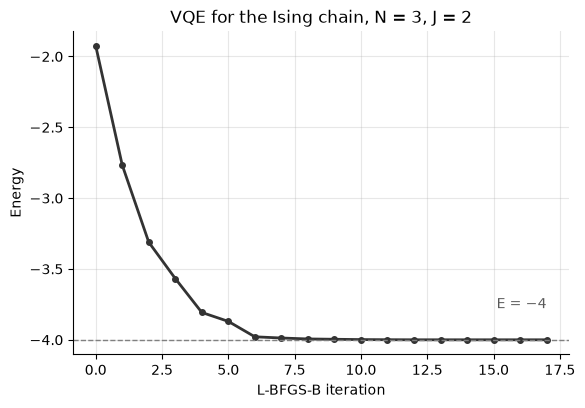

In [164]:
plt.plot(range(len(energy)), energy, color="0.2", lw=2, marker="o", ms=4)
plt.axhline(-4, color="0.5", lw=1, ls="--")
plt.text(len(energy) - 1, -3.8, "E = −4", ha="right", va="bottom", color="0.35")
plt.xlabel("L-BFGS-B iteration")
plt.ylabel("Energy")
plt.title("VQE for the Ising chain, N = 3, J = 2")
plt.show()

All three starts reach $E = -4$, in fewer than 20 iterations. Is that right? Take the first term of the Hamiltonian, $-2\,Z_0 Z_1$. If the first two qubits are both in $|0\rangle$, then $\langle Z_0 Z_1\rangle = (+1)(+1) = +1$, and the term contributes $-2$. If the last two qubits are also in $|0\rangle$, the second term contributes another $-2$, so $E = -4$. With all qubits in $|1\rangle$ the energy is $-4$ as well. No state can do better, since each term contributes at least $-2$: VQE has reached the lowest possible energy.

But which state has it found, $|000\rangle$ or $|111\rangle$? On a simulator we can look at the state itself: `Statevector(circuit)` computes the full quantum state prepared by a circuit, and `probabilities_dict()` gives the probability of each measurement outcome. (On a real quantum computer the state is not accessible: we would have to estimate these probabilities by measuring many times.)

In [165]:
def ket_string(state, tol=0.01):
    # Writes a state as a sum of basis states, e.g. "0.707|000⟩ + 0.707|111⟩", leaving out amplitudes below tol.
    # Multiplying a state by a global phase e^(iφ) changes nothing physical, so we pick the phase
    # that makes the largest amplitude real and positive.
    amplitudes = state.to_dict()  # {"000": amplitude, "001": amplitude, ...}
    largest = max(amplitudes.values(), key=abs)
    terms = []
    for bits, a in amplitudes.items():
        a = a * abs(largest) / largest  # remove the global phase
        if abs(a) > tol:
            coefficient = f"{a.real:.3f}" if abs(a.imag) < 5e-4 else f"({a.real:.3f}{a.imag:+.3f}i)"
            terms.append(f"{coefficient}|{bits}⟩")
    return " + ".join(terms).replace("+ -", "- ")


for run in sorted(runs, key=lambda run: run["start"]):
    psi = Statevector(ansatz.assign_parameters(run["params"]))  # the state prepared with the optimized angles
    probabilities = psi.probabilities_dict()
    print(f"start {run['start']}:  |ψ⟩ = {ket_string(psi)}")
    print(f"          P(000) = {probabilities.get('000', 0):.3f},  P(111) = {probabilities.get('111', 0):.3f}")

start 0:  |ψ⟩ = 0.977|000⟩ + (0.214+0.021i)|111⟩
          P(000) = 0.954,  P(111) = 0.046
start 1:  |ψ⟩ = (0.081-0.279i)|000⟩ + 0.957|111⟩
          P(000) = 0.084,  P(111) = 0.916
start 2:  |ψ⟩ = (0.671-0.224i)|000⟩ + 0.707|111⟩
          P(000) = 0.500,  P(111) = 0.500


The three starts found three different states: start 0 is almost $|000\rangle$, start 1 is almost $|111\rangle$, and start 2 is an equal superposition of the two. The coefficients (amplitudes) are complex numbers, and the square of their magnitude is the probability of that outcome, for example $0.977^2 \approx 0.954$.

All three are correct. $H$ gives the same energy, $-4$, to $|000\rangle$ and $|111\rangle$, and it contains no term that turns one into the other. So every superposition

$$|\psi\rangle = \alpha\,|000\rangle + \beta\,|111\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1,$$

has energy $-4$ as well, whatever $\alpha$ and $\beta$ are, relative phase included. The ground state is **degenerate**: there is a whole family of lowest-energy states, and which one VQE returns depends only on where it starts.

This comes from a symmetry. Flipping every spin turns each $Z_i$ into $-Z_i$ but leaves every product $Z_i Z_{i+1}$ unchanged, so the energy cannot tell "all up" from "all down". The transverse field we add next breaks the tie and leaves a single ground state; Section 5 shows what it looks like.

## 4. Adding a transverse field

Now we add a magnetic field along $x$, perpendicular to the $z$ direction of the interaction. It is called a **transverse field**, and it adds the term $-h_x \sum_i X_i$:

<center><img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_2_transverse_Ising.png" width="30%" alt="The Ising chain in a transverse magnetic field"></center>

$$H = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} \;-\; h_x \sum_{i=0}^{N-1} X_i .$$

The two terms compete, like a tug of war:

- When $J \gg h_x$, the interaction wins and the spins all align along $z$. This is the **ordered** phase.

  <center><img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_3_ground_state_J_large.png" width="50%" alt="Ground state for J much larger than h_x: all spins along z"></center>

- When $h_x \gg J$, the field wins and every spin points along $x$, parallel to the field. Along $z$ they are then completely random. This is the **disordered** phase.

  <center><img src="https://raw.githubusercontent.com/PennyLaneAI/demos/a83efb73d7989aa60917124c25ce0469c02bae02/_static/demonstration_assets/quantum_phase_transitions/Fig_4_ground_state_h_large.png" width="50%" alt="Ground state for h_x much larger than J: all spins along x"></center>

For an infinitely long chain, the switch between the two phases happens sharply at $J/h_x = 1$ [3, 4]. This is the quantum phase transition we want to see.

## 5. Measuring order: the magnetization

To tell the two phases apart we look at the **magnetization**, the average of all the $Z_i$:

$$M = \frac{1}{N} \sum_i Z_i .$$

If you measure all the qubits, $M$ is close to $+1$ or $-1$ in the ordered phase (almost all spins agree), and close to $0$ in the disordered phase (the spins are random).

**A subtlety.** For a chain of finite length, the ordered ground state is not "all up" or "all down", but a *superposition* of the two, roughly $(|00\cdots0\rangle + |11\cdots1\rangle)/\sqrt2$. Each measurement finds an ordered chain, but up and down are equally likely, so the *average* $\langle M\rangle$ is zero, at every $J$. That's why we measure the average of $M^2$ instead: squaring removes the sign. Its square root, $\sqrt{\langle M^2\rangle}$, is the typical size of the magnetization:

- it is close to 1 in the ordered phase;
- it is small in the disordered phase, but not exactly zero for a short chain: even completely random spins give $\sqrt{\langle M^2\rangle} = 1/\sqrt N$.

$M^2 = \frac{1}{N^2} \sum_{i,j} Z_i Z_j$ is again a sum of Pauli strings, so the Estimator can measure it just like the energy.

For small chains we can also compute everything **exactly**, by writing $H$ as a $2^N \times 2^N$ matrix and finding its lowest eigenvector. This is impossible for large $N$, but here it lets us check the VQE results.

In [166]:
def magnetization_op(N):
    # M = (1/N) * sum_i Z_i
    return SparsePauliOp.from_sparse_list([("Z", [i], 1 / N) for i in range(N)], num_qubits=N)


def magnetization_squared_op(N):
    # M^2 = (1/N^2) * sum_ij Z_i Z_j
    M = magnetization_op(N)
    return (M @ M).simplify()


def exact_ground_state(hamiltonian):
    # Lowest energy and corresponding state, by exact diagonalization of the 2^N x 2^N matrix (small N only)
    values, vectors = eigsh(hamiltonian.to_matrix(sparse=True), k=1, which="SA")
    return values[0], vectors[:, 0]


def exact_rms_magnetization(N, J, h_x=1.0):
    # sqrt(<M^2>) in the exact ground state
    psi = Statevector(exact_ground_state(ising_hamiltonian(N, J, h_x))[1])
    return np.sqrt(psi.expectation_value(magnetization_squared_op(N)).real)


print("M^2 for N = 3:", magnetization_squared_op(3))

M^2 for N = 3: SparsePauliOp(['III', 'IZZ', 'ZIZ', 'ZZI'],
              coeffs=[0.33333333+0.j, 0.22222222+0.j, 0.22222222+0.j, 0.22222222+0.j])


## 6. Scanning $J$ for a chain of 5 qubits

We fix the field at $h_x = 1$ and vary $J$, so that $J/h_x$ goes from 0 (field only) to 7.5 (interaction dominates), with more points around the expected transition at $J = 1$. For each value of $J$ we run VQE (three starts, best one kept) and measure the energy and $\langle M^2\rangle$ of the result in a single Estimator call.

In [167]:
N = 5

# h_x is the strength of the transverse magnetic field
h_x = 1

# the values of J (and therefore of J/h_x) that we scan
J_list = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0, 5.0, 7.5]

ansatz_5 = create_ansatz(N)
M2 = magnetization_squared_op(N)
rng = np.random.default_rng(N)  # fixed seed: reproducible starting angles

runs_5, energy_list, m2_list, iterations_list = [], [], [], []
for J in J_list:
    H = ising_hamiltonian(N, J, h_x)
    runs = run_vqe(ansatz_5, H, rng)  # three starts, lowest energy first

    # energy and <M^2> of the best state, from one Estimator call
    E, m2 = estimator.run([(ansatz_5, [H, M2], runs[0]["params"])]).result()[0].data.evs
    runs_5.append(runs)
    energy_list.append(E)
    m2_list.append(m2)
    iterations_list.append(runs[0]["iterations"])

print(f"{'J':>5} {'iterations':>11} {'E':>10} {'sqrt<M2>':>9} {'exact':>7}")
for J, n_it, E, m2 in zip(J_list, iterations_list, energy_list, m2_list):
    print(f"{J:5.2f} {n_it:11d} {E:10.4f} {np.sqrt(m2):9.3f} {exact_rms_magnetization(N, J, h_x):7.3f}")

    J  iterations          E  sqrt<M2>   exact
 0.00          15    -5.0000     0.447   0.447
 0.25         102    -5.0624     0.494   0.497
 0.50          43    -5.2490     0.545   0.558
 0.75          34    -5.5575     0.600   0.633
 0.90          30    -5.7997     0.635   0.682
 1.00          57    -5.9842     0.660   0.716
 1.10          30    -6.1868     0.684   0.749
 1.25          28    -6.5234     0.721   0.794
 1.50         198    -7.1773     0.888   0.856
 2.00         329    -8.8770     0.942   0.927
 5.00          95   -20.3499     0.991   0.991
 7.50          46   -30.2333     0.996   0.996


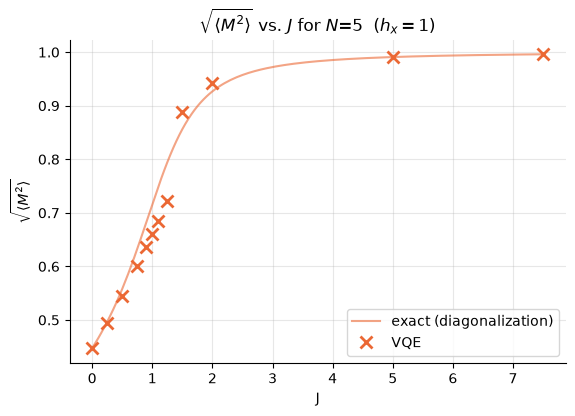

In [168]:
J_dense = np.linspace(0, 7.5, 151)
plt.plot(J_dense, [exact_rms_magnetization(N, J, h_x) for J in J_dense], color=SIZE_COLORS[5], lw=1.5, alpha=0.6,
         label="exact (diagonalization)")
plt.plot(J_list, np.sqrt(m2_list), ls="none", marker="x", ms=8, mew=2, color=SIZE_COLORS[5], label="VQE")
plt.xlabel("J")
plt.ylabel(r"$\sqrt{\langle M^2 \rangle}$")
plt.title(r"$\sqrt{\langle M^2 \rangle}$ vs. $J$ for $N$=" + str(N) + r"  ($h_x = 1$)")
plt.legend(loc="lower right")
plt.show()

$\sqrt{\langle M^2\rangle}$ grows from $1/\sqrt5 \approx 0.45$ at $J = 0$ (random spins) to almost 1 at large $J$ (ordered spins). It rises most steeply around $J \approx 1$, where we expect the transition.

The VQE points (crosses) follow the exact curve closely. The small differences around $J \approx 1$–$1.5$ come from the circuit: with only one layer of CNOTs it cannot represent the true ground state perfectly there. Even so, every VQE energy is within 2% of the exact one (see the table in Section 7).

For 5 qubits the change is gradual rather than abrupt. A truly sharp transition only exists for an infinitely long chain. So what happens when the chain gets longer?

## 7. Longer chains: the transition gets sharper

We now repeat the scan for $N = 4$, 6 and 8 qubits, with the same values of $J$. For every point we also compute the exact values, for comparison. This is a longer test: it takes two to three minutes, mostly for $N = 8$.

In [169]:
sizes = [4, 6, 8]


def magnetization_scan(N, J_list, h_x=1.0):
    # The N = 5 scan above, for any N (starting angles from a generator seeded with N)
    ansatz = create_ansatz(N)
    M2 = magnetization_squared_op(N)
    rng = np.random.default_rng(N)
    out = {"runs": [], "E": [], "M2": [], "iterations": []}
    for J in J_list:
        H = ising_hamiltonian(N, J, h_x)
        runs = run_vqe(ansatz, H, rng)
        E, m2 = estimator.run([(ansatz, [H, M2], runs[0]["params"])]).result()[0].data.evs
        for key, value in zip(out, (runs, E, m2, runs[0]["iterations"])):
            out[key].append(value)
    return {key: (value if key == "runs" else np.array(value)) for key, value in out.items()}


scan = {5: {"runs": runs_5, "E": np.array(energy_list), "M2": np.array(m2_list),
            "iterations": np.array(iterations_list)}}
for N in sizes:
    scan[N] = magnetization_scan(N, J_list, h_x)

# exact ground-state energy and sqrt(<M^2>), for comparison
for N in scan:
    M2 = magnetization_squared_op(N)
    exact = [exact_ground_state(ising_hamiltonian(N, J, h_x)) for J in J_list]
    scan[N]["E0"] = np.array([e0 for e0, _ in exact])
    scan[N]["exact_rms"] = np.array([np.sqrt(Statevector(psi).expectation_value(M2).real) for _, psi in exact])

In [170]:
sizes = sorted(scan)
print("For each N: sqrt<M^2> from VQE, the exact value, and the relative energy error of VQE |E_VQE - E0| / |E0|\n")
print(" " * 6 + "".join(f"{'N = ' + str(N):^26}" for N in sizes))
print(f"{'J':>5} " + "".join(f"{'VQE':>8}{'exact':>8}{'error':>8}  " for N in sizes))
for k, J in enumerate(J_list):
    row = f"{J:5.2f} "
    for N in sizes:
        d = scan[N]
        error = abs(d["E"][k] - d["E0"][k]) / abs(d["E0"][k])
        row += f"{np.sqrt(d['M2'][k]):8.3f}{d['exact_rms'][k]:8.3f}{error:8.2%}  "
    print(row)

For each N: sqrt<M^2> from VQE, the exact value, and the relative energy error of VQE |E_VQE - E0| / |E0|

                N = 4                     N = 5                     N = 6                     N = 8           
    J      VQE   exact   error       VQE   exact   error       VQE   exact   error       VQE   exact   error  
 0.00    0.500   0.500   0.00%     0.447   0.447   0.00%     0.408   0.408   0.00%     0.354   0.354   0.00%  
 0.25    0.549   0.551   0.00%     0.494   0.497   0.00%     0.453   0.456   0.00%     0.394   0.397   0.00%  
 0.50    0.600   0.610   0.04%     0.545   0.558   0.06%     0.503   0.517   0.06%     0.441   0.457   0.07%  
 0.75    0.654   0.676   0.20%     0.600   0.633   0.26%     0.558   0.598   0.30%     0.494   0.543   0.35%  
 0.90    0.686   0.717   0.37%     0.635   0.682   0.50%     0.594   0.655   0.59%     0.530   0.612   0.71%  
 1.00    0.708   0.744   0.52%     0.660   0.716   0.70%     0.619   0.695   0.85%     0.555   0.664   1.05%  
 1.10

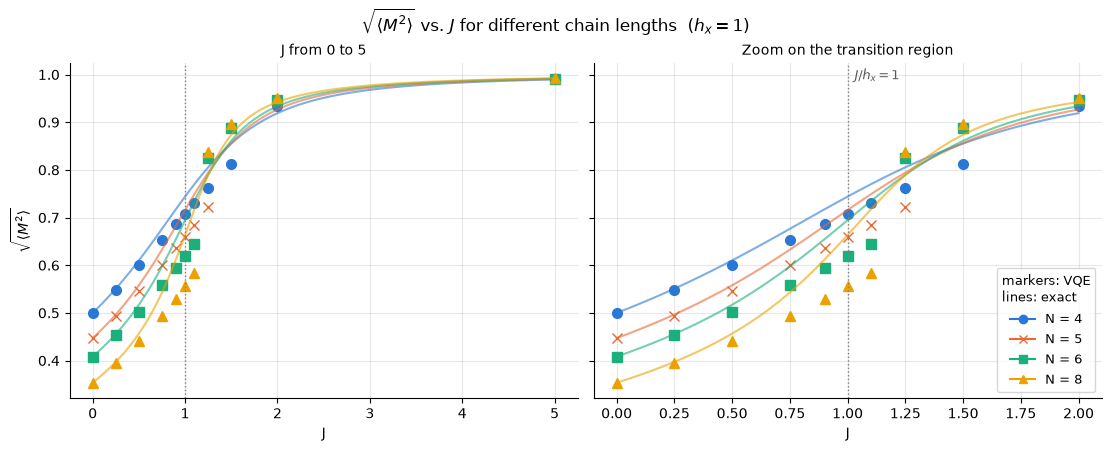

In [171]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout="constrained")
J_arr = np.array(J_list)
J_dense = np.linspace(0, 5, 101)
exact_dense = {N: np.array([exact_rms_magnetization(N, J, h_x) for J in J_dense]) for N in sizes}

for ax, J_max, title in zip(axes, (5.0, 2.0), ("J from 0 to 5", "Zoom on the transition region")):
    shown, dense = J_arr <= J_max, J_dense <= J_max
    for N in sizes:
        ax.plot(J_dense[dense], exact_dense[N][dense], color=SIZE_COLORS[N], lw=1.5, alpha=0.6)
        ax.plot(J_arr[shown], np.sqrt(scan[N]["M2"][shown]), ls="none", marker=SIZE_MARKERS[N], ms=7,
                color=SIZE_COLORS[N])
    ax.axvline(1.0, color="0.5", lw=1, ls=":")
    ax.set_xlabel("J")
    ax.set_title(title, fontsize=10)

axes[0].set_ylabel(r"$\sqrt{\langle M^2 \rangle}$")
axes[1].text(1.03, 0.98, r"$J/h_x = 1$", transform=axes[1].get_xaxis_transform(), color="0.35", fontsize=9, va="top")
handles = [Line2D([], [], color=SIZE_COLORS[N], marker=SIZE_MARKERS[N], lw=1.5, label=f"N = {N}") for N in sizes]
axes[1].legend(handles=handles, loc="lower right", title="markers: VQE\nlines: exact", fontsize=9, title_fontsize=9)
fig.suptitle(r"$\sqrt{\langle M^2 \rangle}$ vs. $J$ for different chain lengths  ($h_x = 1$)")
plt.show()

What the curves show:

- **At $J = 0$** every curve starts at $1/\sqrt N$ (0.500, 0.447, 0.408 and 0.354 for $N$ = 4, 5, 6 and 8): the spins are completely random.
- **The curves get steeper as $N$ grows.** Below the transition, longer chains give smaller values (at $J = 0.5$: 0.600, 0.545, 0.503, 0.441); above it, longer chains give larger values (at $J = 2$: 0.935, 0.942, 0.946, 0.950). This is how a phase transition shows up in finite systems: the change becomes sharper and sharper as the system grows, and for an infinitely long chain it becomes a sudden jump at $J/h_x = 1$.
- **VQE agrees well with the exact results** away from the transition. The differences are largest near $J \approx 1$, up to about 0.13 for $N = 8$, because the simple one-layer circuit cannot capture all the correlations between the spins there. Exercise 2 below explores how to improve this.

## 8. Going further: the Binder cumulant, exact solution vs VQE (optional)

The curves above show *that* the transition sharpens, but not exactly *where* it is. A standard trick, invented for computer simulations of magnets, is the **Binder cumulant**

$$U_4 = 1 - \frac{\langle M^4\rangle}{3\langle M^2\rangle^2}.$$

It is close to 0 when the spins are disordered and close to $2/3$ when they are ordered. At the transition it hardly depends on the length of the chain, so the curves for different $N$ **cross** there.

We compute $U_4$ in two ways and compare them:

1. **Exactly**, from the exact ground states (Section 5), for chains of up to 10 qubits and many values of $J$. This is a classical calculation, possible only for short chains.
2. **From the VQE states** of Sections 6 and 7, as a quantum computer would do it: the Estimator measures $\langle M^2\rangle$ and $\langle M^4\rangle$ on the circuit with the optimized angles. We don't need to run VQE again: `scan[N]["runs"]` keeps, for each $J$, the angles of the three runs, the best one first. $M^4 = M^2 M^2$ contains only $Z$s, like $M^2$, so on a real device both come from the same measurements.

> **Hint: two kinds of state, two tools.**
>
> - The **exact ground state** is just a vector of $2^N$ amplitudes, returned by `exact_ground_state`: no circuit prepares it. To compute expectation values in it, wrap it in a `Statevector` and use its `expectation_value` method. The result is a complex number with zero imaginary part, so take `.real`: `Statevector(psi).expectation_value(M2).real`.
> - A **VQE state** is *prepared by a circuit* with the optimized angles, as on a quantum computer, so you measure it with the Estimator, as in Sections 6 and 7. One call measures both observables, and the values are already real: `estimator.run([(circuit, [M2, M4], angles)]).result()[0].data.evs`.

Each of the next two cells takes a few seconds.

In [172]:
# 1. Exact U_4, from the exact ground states, on a fine grid of J and for chains of up to 10 qubits
J_fine = np.linspace(0.25, 2.5, 91)
binder_sizes = [4, 6, 8, 10]

binder = {}
for N in binder_sizes:
    M = magnetization_op(N)
    M2 = (M @ M).simplify()
    M4 = (M2 @ M2).simplify()
    U = []
    for J in J_fine:
        psi = Statevector(exact_ground_state(ising_hamiltonian(N, J, h_x))[1])
        m2, m4 = psi.expectation_value(M2).real, psi.expectation_value(M4).real
        U.append(1 - m4 / (3 * m2**2))
    binder[N] = np.array(U)

In [173]:
# 2. U_4 from the VQE states of Sections 6 and 7
#    (no new optimization: the best angles are stored in scan[N]["runs"])
vqe_sizes = [4, 6, 8]

vqe_binder = {}
for N in vqe_sizes:
    circuit = create_ansatz(N)  # the circuit used in the scans
    M2 = magnetization_squared_op(N)
    M4 = (M2 @ M2).simplify()
    U = []
    for J, runs in zip(J_list, scan[N]["runs"]):
        # the Estimator measures <M^2> and <M^4> on the circuit with the best angles
        m2, m4 = estimator.run([(circuit, [M2, M4], runs[0]["params"])]).result()[0].data.evs
        U.append(1 - m4 / (3 * m2**2))
    vqe_binder[N] = np.array(U)

print("Binder cumulant U_4 from the VQE states (compare with the exact curves in the plot below)\n")
print(f"{'J':>5}" + "".join(f"{'N = ' + str(N):>9}" for N in vqe_sizes))
for k, J in enumerate(J_list):
    print(f"{J:5.2f}" + "".join(f"{vqe_binder[N][k]:9.3f}" for N in vqe_sizes))

Binder cumulant U_4 from the VQE states (compare with the exact curves in the plot below)

    J    N = 4    N = 6    N = 8
 0.00    0.167    0.111    0.083
 0.25    0.232    0.161    0.123
 0.50    0.301    0.218    0.169
 0.75    0.369    0.283    0.226
 0.90    0.407    0.326    0.266
 1.00    0.432    0.355    0.295
 1.10    0.455    0.384    0.327
 1.25    0.488    0.571    0.595
 1.50    0.534    0.613    0.626
 2.00    0.630    0.644    0.650
 5.00    0.662    0.663    0.664
 7.50    0.665    0.665    0.666


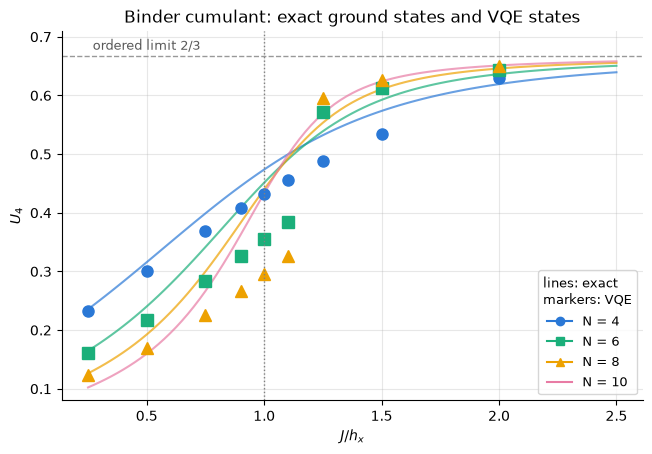

In [174]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7.5, 4.8))
J_arr = np.array(J_list)
shown = (J_arr >= J_fine[0]) & (J_arr <= J_fine[-1])  # the values of J inside the range of the exact curves
for N in binder_sizes:
    ax.plot(J_fine, binder[N], color=SIZE_COLORS[N], lw=1.5, alpha=0.7)  # exact
for N in vqe_sizes:
    ax.plot(J_arr[shown], vqe_binder[N][shown], ls="none", marker=SIZE_MARKERS[N], ms=8, color=SIZE_COLORS[N])  # VQE
ax.axvline(1.0, color="0.5", lw=1, ls=":")
ax.axhline(2 / 3, color="0.6", lw=1, ls="--")
ax.text(0.27, 2 / 3 + 0.006, "ordered limit 2/3", ha="left", va="bottom", color="0.35", fontsize=9)
ax.set_ylim(0.08, 0.71)
ax.set_xlabel(r"$J/h_x$")
ax.set_ylabel(r"$U_4$")
ax.set_title("Binder cumulant: exact ground states and VQE states")
handles = [Line2D([], [], color=SIZE_COLORS[N], marker=SIZE_MARKERS[N] if N in vqe_sizes else None, lw=1.5,
                  label=f"N = {N}") for N in binder_sizes]
ax.legend(handles=handles, loc="lower right", title="lines: exact\nmarkers: VQE", fontsize=9, title_fontsize=9)
plt.show()

What the two calculations show:

- **The exact curves cross close to $J/h_x = 1$**: a little above 1 for the shortest chains, and closer to 1 for the longest ones (look where the $N = 8$ and $N = 10$ curves meet). With longer and longer chains the crossings would converge to the exact value, $J/h_x = 1$.
- **Far from the transition, VQE agrees with the exact results.** At $J = 0$ the VQE values are 0.167, 0.111 and 0.083: exactly $2/(3N)$, the value for completely random spins. At $J = 2$ the VQE points sit almost on the exact curves.
- **Just below the transition the VQE values are too low, and more so for longer chains.** At $J = 1$ VQE gives 0.432 for $N = 4$, a little below the exact curve (about 0.47), but 0.295 for $N = 8$, far below it (about 0.44). With a single layer of CNOTs the circuit cannot build all the correlations between distant spins (Section 7), and $U_4$ is affected even more than $\sqrt{\langle M^2\rangle}$.
- **At $J = 1.25$ the VQE values for $N = 6$ and 8 jump above the exact curves** (0.571 and 0.595, where the exact curves are at about 0.54 and 0.55). There the optimizer has found a state that is more ordered than the true ground state: the same jump appears in $\sqrt{\langle M^2\rangle}$ in the table of Section 7.
- **So the VQE curves cross too, between $J = 1.1$ and $1.25$, but because of this jump**, not through the smooth curves that the method relies on. With VQE points only every 0.1 to 0.25 in $J$, we also cannot place the crossing as precisely as with the exact curves.

**A deeper circuit fixes this.** With three layers of rotations and CNOTs (Qiskit's `efficient_su2(N, su2_gates=["rz", "rx", "rz"], entanglement="linear", reps=3)`, with $12N$ angles), the VQE values fall on the exact curves: at $J = 1$, for example, $N = 8$ gives 0.425, close to the exact 0.44, and the curves cross smoothly between $J = 1.1$ and 1.25. The price is time: the scans of Section 7 take about half an hour instead of two to three minutes, which is why we use a single layer here. Exercise 2 lets you try a deeper circuit.

## 9. Supplementary: from a chain to a square lattice (for those who finish)

If you have finished, adapt what you have done to the **two-dimensional** Ising model: $N = L \times L$ qubits on a square lattice, each interacting with its neighbours on the left, on the right, above and below. The Hamiltonian has the same form as before,

$$H = -J \sum_{\langle i,j\rangle} Z_i Z_j \;-\; h_x \sum_{i=0}^{N-1} X_i ,$$

but the first sum now runs over all the pairs $\langle i,j\rangle$ of neighbouring sites, the *bonds* of the lattice, horizontal and vertical. The transition moves too: for an infinitely large lattice it is at $J/h_x \approx 0.33$ (the critical field is $h_x \approx 3.04\,J$) [6], instead of 1. In small lattices, as in short chains, the change is gradual and appears at somewhat larger values of $J$.

You already have almost all the pieces. Some hints:

1. **Number the qubits.** Give the site in row $r$ and column $c$ the index $i = rL + c$. For $L = 3$:
   ```
   0 — 1 — 2
   |   |   |
   3 — 4 — 5
   |   |   |
   6 — 7 — 8
   ```
2. **List the bonds.** Write a function `lattice_bonds(L)` that returns the pairs `(i, j)` of neighbouring qubits: for each site, its neighbour on the right (unless the site is in the last column) and the one below (unless it is in the last row). With open boundaries, as for our chain, $L = 2$ has 4 bonds and $L = 3$ has 12.
3. **The Hamiltonian.** Adapt `ising_hamiltonian` into `ising_hamiltonian_2d(L, J, h_x)`, with one $ZZ$ term for each bond. Check it with `exact_ground_state`: for $h_x = 0$ the lowest energy is $-J$ times the number of bonds.
4. **Reuse.** `run_vqe`, the Estimator, `magnetization_op` and `magnetization_squared_op` (with $N = L^2$), and `exact_ground_state` work as they are.
5. **The circuit.** `create_ansatz(L * L)` still works: its CNOTs connect the qubits in the order 0, 1, 2, …, which follows the rows but not the vertical bonds. You can also let the CNOTs follow the lattice: `efficient_su2(L * L, su2_gates=["rz", "rx", "rz"], entanglement=lattice_bonds(L), reps=1)` puts one CNOT on each bond. Try both.
6. **The scan.** Start with $L = 2$ (4 qubits), then $L = 3$ (9 qubits). Put more values of $J$ where the transition is. Larger lattices are too slow for VQE here: $L = 4$ already has 16 qubits. Compare with the exact results, as in Section 6.

### A possible solution

The cells below are one way to do it. They build the 2D Hamiltonian and two circuits, the chain of CNOTs of `create_ansatz` and one CNOT on each bond of the lattice, and compare VQE with exact diagonalization for $L = 2$ and $L = 3$. The scan takes about five minutes.

In [175]:
def lattice_bonds(L):
    # pairs of neighbouring qubits of an L x L square lattice with open boundaries;
    # the site in row r and column c is the qubit r * L + c
    bonds = []
    for r in range(L):
        for c in range(L):
            i = r * L + c
            if c + 1 < L:
                bonds.append((i, i + 1))  # neighbour on the right
            if r + 1 < L:
                bonds.append((i, i + L))  # neighbour below
    return bonds


def ising_hamiltonian_2d(L, J, h_x=0.0):
    # H = -J * sum over the bonds of Z_i Z_j  -  h_x * sum_i X_i
    N = L * L
    terms = [("ZZ", [i, j], -J) for i, j in lattice_bonds(L)]
    if h_x != 0:
        terms += [("X", [i], -h_x) for i in range(N)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=N)


def lattice_ansatz(L):
    # the same rotations as create_ansatz, but with one CNOT on each bond of the lattice
    return efficient_su2(L * L, su2_gates=["rz", "rx", "rz"], entanglement=lattice_bonds(L), reps=1)


# check: for h_x = 0 the lowest energy is -J times the number of bonds
for L in (2, 3):
    E0 = exact_ground_state(ising_hamiltonian_2d(L, 1.0))[0]
    print(f"L = {L}: {len(lattice_bonds(L))} bonds, lowest energy for J = 1 and h_x = 0: {E0:.4f}")

L = 2: 4 bonds, lowest energy for J = 1 and h_x = 0: -4.0000
L = 3: 12 bonds, lowest energy for J = 1 and h_x = 0: -12.0000


In [176]:
J_list_2d = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5]

results_2d = {}
for L in (2, 3):
    N = L * L
    M2 = magnetization_squared_op(N)
    exact = [exact_ground_state(ising_hamiltonian_2d(L, J, h_x)) for J in J_list_2d]
    results_2d[L] = {"E0": np.array([e0 for e0, _ in exact]),
                     "exact_rms": np.array([np.sqrt(Statevector(psi).expectation_value(M2).real) for _, psi in exact])}
    for name, circuit in (("chain", create_ansatz(N)), ("lattice", lattice_ansatz(L))):
        rng = np.random.default_rng(N)  # the same starting angles for both circuits
        E_list, rms_list = [], []
        for J in J_list_2d:
            H = ising_hamiltonian_2d(L, J, h_x)
            runs = run_vqe(circuit, H, rng)
            E, m2 = estimator.run([(circuit, [H, M2], runs[0]["params"])]).result()[0].data.evs
            E_list.append(E)
            rms_list.append(np.sqrt(m2))
        results_2d[L][name] = {"E": np.array(E_list), "rms": np.array(rms_list)}

for L in (2, 3):
    d = results_2d[L]
    print(f"L = {L} ({L * L} qubits)")
    print(f"{'':5}  {'sqrt<M^2>':^26}   {'energy error |E - E0|/|E0|':^26}")
    print(f"{'J':>5}  {'exact':>8}{'chain':>9}{'lattice':>9}   {'chain':>13}{'lattice':>13}")
    for k, J in enumerate(J_list_2d):
        errors = [abs(d[name]["E"][k] - d["E0"][k]) / abs(d["E0"][k]) for name in ("chain", "lattice")]
        print(f"{J:5.2f}  {d['exact_rms'][k]:8.3f}{d['chain']['rms'][k]:9.3f}{d['lattice']['rms'][k]:9.3f}   "
              f"{errors[0]:13.2%}{errors[1]:13.2%}")
    print()

L = 2 (4 qubits)
               sqrt<M^2>            energy error |E - E0|/|E0|
    J     exact    chain  lattice           chain      lattice
 0.00     0.500    0.500    0.500           0.00%        0.00%
 0.10     0.526    0.513    0.514           0.13%        0.11%
 0.20     0.556    0.528    0.529           0.50%        0.44%
 0.30     0.589    0.545    0.539           1.13%        1.17%
 0.40     0.626    0.565    0.556           1.99%        1.91%
 0.50     0.665    0.590    0.569           3.07%        3.12%
 0.60     0.707    0.621    0.607           4.29%        4.66%
 0.80     0.787    0.809    0.810           5.21%        5.00%
 1.00     0.853    0.890    0.887           3.76%        3.60%
 1.50     0.940    0.955    0.954           1.25%        1.20%

L = 3 (9 qubits)
               sqrt<M^2>            energy error |E - E0|/|E0|
    J     exact    chain  lattice           chain      lattice
 0.00     0.333    0.333    0.333           0.00%        0.00%
 0.10     0.358    0

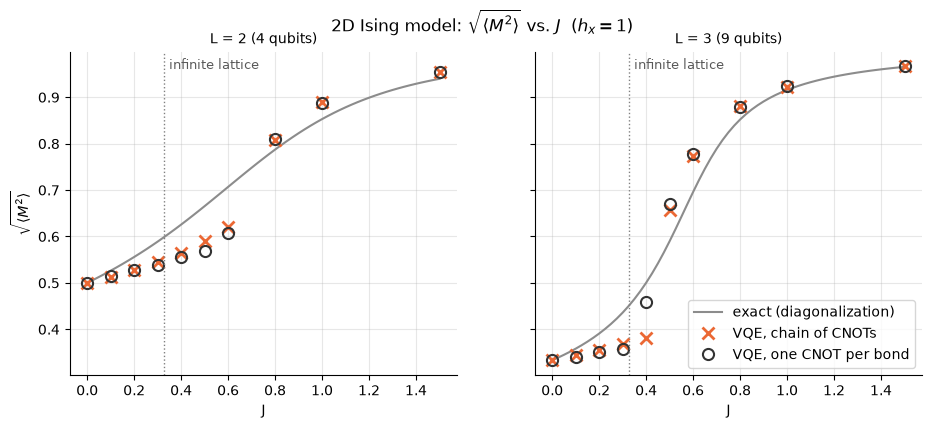

In [177]:
J_dense_2d = np.linspace(0, 1.5, 61)
J_c = 1 / 3.044  # transition of the infinite square lattice, J/h_x

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, L in zip(axes, (2, 3)):
    N = L * L
    M2 = magnetization_squared_op(N)
    exact_dense = [np.sqrt(Statevector(exact_ground_state(ising_hamiltonian_2d(L, J, h_x))[1]).expectation_value(M2).real)
                   for J in J_dense_2d]
    ax.plot(J_dense_2d, exact_dense, color="0.55", lw=1.5, label="exact (diagonalization)")
    ax.plot(J_list_2d, results_2d[L]["chain"]["rms"], ls="none", marker="x", ms=8, mew=2, color=SIZE_COLORS[5],
            label="VQE, chain of CNOTs")
    ax.plot(J_list_2d, results_2d[L]["lattice"]["rms"], ls="none", marker="o", ms=8, mew=1.5, mfc="none", color="0.2",
            label="VQE, one CNOT per bond")
    ax.axvline(J_c, color="0.5", lw=1, ls=":")
    ax.text(J_c + 0.02, 0.98, "infinite lattice", transform=ax.get_xaxis_transform(), color="0.35", fontsize=9, va="top")
    ax.set_xlabel("J")
    ax.set_title(f"L = {L} ({N} qubits)", fontsize=10)
axes[0].set_ylabel(r"$\sqrt{\langle M^2 \rangle}$")
axes[1].legend(loc="lower right")
fig.suptitle(r"2D Ising model: $\sqrt{\langle M^2 \rangle}$ vs. $J$  ($h_x = 1$)")
plt.show()

What the solution shows:

- **The transition moves to smaller $J$.** With up to four neighbours instead of two, each spin is pulled more strongly towards its neighbours, so a smaller $J$ is enough to order the lattice. For $L = 3$ the exact $\sqrt{\langle M^2\rangle}$ rises fastest between $J = 0.4$ and $0.6$ (from 0.500 to 0.696), much earlier than in the chain, where the rise is around $J = 1$, but still above the infinite-lattice value $J/h_x \approx 0.33$, as expected for such a small system. For $L = 2$ the rise is more gradual.
- **VQE has more trouble in 2D.** The energy errors reach about 5% for $L = 2$ and 3.7% for $L = 3$, against at most 1.8% in the chain: each spin now has more neighbours to be correlated with, and a single layer of CNOTs can build only a limited amount of correlation. Below the transition VQE underestimates $\sqrt{\langle M^2\rangle}$, and for $L = 3$ at $J = 0.5$ it jumps above the exact curve, as in 1D.
- **With one layer, letting the CNOTs follow the lattice hardly helps.** The two circuits give very similar results: their energy errors differ by at most 0.6 percentage points, and only for $L = 3$ at $J = 0.4$ is $\sqrt{\langle M^2\rangle}$ clearly closer to the exact value. As in 1D, more layers would be the next thing to try (Exercise 2).

## 10. What changes on a real quantum computer?

Everything quantum in this notebook goes through the Estimator (apart from the look at the three-qubit states in Section 3, which only a simulator allows), so the same code can run on real hardware by replacing the Aer Estimator with the Estimator of a quantum computer (for IBM devices, from the `qiskit-ibm-runtime` package). A few things change:

- the circuit must first be **transpiled**: rewritten in the device's native gates and mapped onto its physical qubits;
- each expectation value is estimated from a finite number of measurements (**shots**), so it comes with statistical noise, on top of the noise of the device itself;
- optimizers that cope better with noisy measurements, such as SPSA or COBYLA, are then preferred to L-BFGS-B.

Measuring $M^2$ costs nothing extra: it contains only $Z$s, so it comes from the same measurements as the $ZZ$ terms of the energy.

## Summary

- The **Ising model in a transverse field** has two phases: ordered (spins aligned along $z$) when $J \gg h_x$, and disordered when $h_x \gg J$. For a long chain, the quantum phase transition between them is at $J/h_x = 1$.
- **VQE** finds the ground state by minimizing the energy of a parameterized circuit. Here: the hardware-efficient ansatz, energies and gradients from Qiskit's Estimator, and SciPy's L-BFGS-B optimizer started from three random points.
- The **size of the magnetization**, $\sqrt{\langle M^2\rangle}$, tracks the order. Its curves get steeper as the chain grows: the finite-size signature of the transition. The Binder cumulant locates it close to $J/h_x = 1$.

## Exercises

1. **Why not just $\langle M\rangle$?** The three VQE runs at $N = 5$, $J = 2$ are stored in `runs_5[J_list.index(2.0)]`. For each, measure $\langle M\rangle$ with `estimator.run([(ansatz_5, magnetization_op(5), run["params"])]).result()[0].data.evs`, and compare with $\sqrt{\langle M^2\rangle}$. What do you notice, and how does it relate to the "subtlety" in Section 5?
2. **A better circuit.** Give the ansatz two layers: repeat steps 2 and 3 of `create_ansatz` with new angles, or use Qiskit's `n_local(N, ["rz", "rx", "rz"], "cx", entanglement="linear", reps=2)` from `qiskit.circuit.library`. Does VQE get closer to the exact curve near $J = 1$? (The runs take longer.)
3. **A different field.** Set $h_x = 0.5$ and repeat the scan for $N = 5$. Where do you expect the transition now? Does the curve agree?
4. **A ring instead of a line.** Add the bond between the last and the first qubit to the Hamiltonian (and a CNOT between them in the ansatz). How do the results change?

## References

1. D. Pope and T. Shah, ["Seeing quantum phase transitions with quantum computers"](https://pennylane.ai/qml/demos/tutorial_quantum_phase_transitions), PennyLane demo (2025).
2. A. Kandala et al., "Hardware-efficient Variational Quantum Eigensolver for Small Molecules and Quantum Magnets", [arXiv:1704.05018](https://arxiv.org/abs/1704.05018) (2017).
3. S. Sachdev, *Quantum Phase Transitions*, 2nd ed., Cambridge University Press (2011).
4. P. Pfeuty, "The one-dimensional Ising model with a transverse field", Ann. Phys. **57**, 79 (1970).
5. K. Binder, "Finite size scaling analysis of Ising model block distribution functions", Z. Phys. B **43**, 119 (1981).
6. H. W. J. Blöte and Y. Deng, "Cluster Monte Carlo simulation of the transverse Ising model", Phys. Rev. E **66**, 066110 (2002).